# Many pairs: pooled seed-set models

So far each seed-set model was fitted on one graph pair (one A, one B), so its weights describe that pair. Following Prof. Lyzinski's suggestion, this collects the same kind of data on many fresh pairs and fits one pooled model per setting. The pooled weighted score is what best of N will use to screen random seed sets.

**Design** (details in `multi_pair_collection.py`)
- **Pairs.** Fresh, structure-checked pairs with round 1's graph settings, from a new seed stream. They never coincide with round-1 or borderline pairs, so those stay free for testing. FAQ and GOAT share pairs.
- **Budget.** One per setting, where a single run from a random set succeeded about half the time on round 1's pairs (FAQ ER is probably lower, about a third).
- **500 seed sets per pair, one run each.** All are random sets. The tail and contrast sets are picked from a 20,000-set random pool by their graph-A features, never by outcomes.

| Group | Sets | Purpose |
|---|---|---|
| random | 300 | the population best of N screens; used to evaluate the model |
| tail | 100 | the top 5% of the pool in degree, pair mass, uniqueness or their sum: where best of N picks |
| contrast | 100 | 50 degree-matched pairs, low against high pair mass or uniqueness: separates them from degree |

| | ER | PAPER | Chung–Lu | Pairs per model |
|---|---|---|---|---|
| Percolation | 8 | 7 | 5 | 50 |
| GOAT | 15 | 12 | 9 | 32 |
| FAQ | 29 | 29 | 27 | 24 |

**Model.** Logistic regression of success on four core features: degree, harmonic, pair mass and uniqueness (cap 3; cap 2 for FAQ). Each feature is a z-score against the pair's own random sets, and each pair gets its own baseline, so the weights describe "better than other sets on the same graph". That is exactly the comparison best of N makes. Pairs where every set succeeds, or every set fails, carry no information under this model and are left out of the fit.

**Run time.** About 35–40 hours with 3 pairs at a time (the printed estimate is the cautious one): percolation about 4 h, GOAT about 15–16 h, FAQ about 15–18 h. For 1,000 sets per pair, set `SETS_PER_PAIR = 1000` and halve `PAIRS` before the first run; this can't be changed for pairs already started. Pairs run in order of pair index across all settings, and rows are written set by set. Stopping early therefore just means fewer pairs everywhere, and rerunning resumes where it stopped. The analysis below uses the pairs that are complete; the held-out sections need at least 5 per setting.

| Section | Content |
|---|---|
| 1 | Label balance |
| 2 | Pooled weights, and how much they vary between pairs |
| 3 | New pairs: does the score rank seed sets it hasn't seen? |
| 4 | Degree-matched contrasts |
| 5 | Save the pooled weights for best of N |

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

PACKAGE_DIR = Path.cwd().resolve()
if PACKAGE_DIR.name != 'fixed_pair_seed_set_classification':
    PACKAGE_DIR = PACKAGE_DIR / 'fixed_pair_seed_set_classification'
if str(PACKAGE_DIR.parent) not in sys.path:
    sys.path.insert(0, str(PACKAGE_DIR.parent))

from fixed_pair_seed_set_classification import multi_pair_collection as MP

RUN_COLLECTION = True                                 # False: only analyse saved results
ALGORITHMS_TO_RUN = ['percolation', 'goat', 'faq']    # remove any to skip it
PAIRS = dict(MP.N_PAIRS)                              # pairs per graph model: percolation 50, GOAT 32, FAQ 24
SETS_PER_PAIR = 500                                   # 60% random, 20% tail, 20% contrast
JOBS = 3                                              # pairs run in parallel
MIN_PAIRS = 5                                         # complete pairs a setting needs before it is analysed
GROUPS = MP.groups_for(SETS_PER_PAIR)

FEATURES = list(MP.CORE_FEATURES)
FEATURE_COLORS = {'degree': '#222222', 'harmonic': '#8C6D31', 'pair_mass': '#1F77B4', 'uniqueness': '#2CA02C'}

## Run

The cell below prints an estimate, then one line per finished pair with the time left. The interrupt button stops the workers too, and rerunning skips finished pairs and resumes a stopped pair from its last written set.

For a run over the weekend, a terminal is sturdier than a notebook. From the repository root:
- `python -m fixed_pair_seed_set_classification.multi_pair_collection` runs everything (Ctrl-C stops it);
- `... --status` shows how far it is;
- `... --sets-per-pair 1000 --pairs percolation=25 goat=16 faq=12` gives 1,000 sets per pair instead.

Then set `RUN_COLLECTION = False` here (and the same `SETS_PER_PAIR` and `PAIRS`) to analyse.

In [2]:
if RUN_COLLECTION:
    MP.run_all(ALGORITHMS_TO_RUN, n_pairs=PAIRS, jobs=JOBS, groups=GROUPS)
display(MP.status(n_pairs=PAIRS, groups=GROUPS))

All planned pairs are complete. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/fixed_pair_seed_set_classification/data/multi_pair_2026-10-30


budget  pairs planned  pairs complete  pairs started  \
algorithm   model                                                            
Percolation ER             8             50              50             50   
            PAPER          7             50              50             50   
            Chung-Lu       5             50              50             50   
GOAT        ER            15             32              32             32   
            PAPER         12             32              32             32   
            Chung-Lu       9             32              32             32   
SGM (FAQ)   ER            29             24              24             24   
            PAPER         29             24              24             24   
            Chung-Lu      27             24              24             24   

                      sets written  
algorithm   model                   
Percolation ER               25000  
            PAPER            25000  
            Chung-Lu         25000  
GOAT        ER               16000  
            PAPER            16000  
            Chung-Lu         16000  
SGM (FAQ)   ER               12000  
            PAPER            12000  
            Chung-Lu         12000

## 1. Label balance

For the model to learn anything, a pair needs both successes and failures among its sets.
- **random success:** the average success rate of the random sets, over pairs. The budgets aim for about 50%.
- **pairs with 10–90% random success:** the most informative pairs.
- **tail success:** the average success rate of the tail sets in each direction. If it is clearly above random success, picking sets from the top of that feature already helps.

In [3]:
data = MP.load_sets()
settings = [(a, m) for a in MP.ALGORITHMS for m in MP.MODELS
            if data.loc[(data['algorithm'] == a) & (data['model'] == m), 'pair_index'].nunique() > 0]
rows = []
for algorithm, model in settings:
    part = data[(data['algorithm'] == algorithm) & (data['model'] == model)]
    random_rate = part[part['group'] == 'random'].groupby('pair_index')['success'].mean()
    tail = part[part['group'] == 'tail'].groupby('direction')['success'].mean()
    rows.append({'algorithm': MP.ALGORITHM_LABELS[algorithm], 'model': MP.MODEL_LABELS[model],
                 'pairs': part['pair_index'].nunique(), 'random success': random_rate.mean(),
                 'pairs with 10-90% random success': int(((random_rate >= 0.1) & (random_rate <= 0.9)).sum()),
                 **{f'tail success: {MP.FEATURE_LABELS.get(d, d)}': tail.get(d, np.nan) for d in MP.TAIL_DIRECTIONS}})
display(pd.DataFrame(rows).set_index(['algorithm', 'model']).round(2))
analysed = [(a, m) for a, m in settings
            if data.loc[(data['algorithm'] == a) & (data['model'] == m), 'pair_index'].nunique() >= MIN_PAIRS]
print('Settings with at least', MIN_PAIRS, 'complete pairs:',
      ', '.join(f'{MP.ALGORITHM_LABELS[a]} {MP.MODEL_LABELS[m]}' for a, m in analysed) or 'none yet')

pairs  random success  pairs with 10-90% random success  \
algorithm   model                                                               
Percolation ER           50            0.57                                50   
            PAPER        50            0.56                                50   
            Chung-Lu     50            0.50                                50   
GOAT        ER           32            0.59                                31   
            PAPER        32            0.55                                30   
            Chung-Lu     32            0.52                                32   
SGM (FAQ)   ER           24            0.40                                24   
            PAPER        24            0.45                                24   
            Chung-Lu     24            0.60                                24   

                      tail success: degree  tail success: pair mass  \
algorithm   model                                                     
Percolation ER                        0.81                     0.85   
            PAPER                     0.84                     0.88   
            Chung-Lu                  0.75                     0.81   
GOAT        ER                        0.76                     0.76   
            PAPER                     0.63                     0.62   
            Chung-Lu                  0.52                     0.51   
SGM (FAQ)   ER                        0.61                     0.64   
            PAPER                     0.70                     0.64   
            Chung-Lu                  0.72                     0.71   

                      tail success: uniqueness  tail success: combined  
algorithm   model                                                       
Percolation ER                            0.79                    0.87  
            PAPER                         0.77                    0.88  
            Chung-Lu                      0.70                    0.81  
GOAT        ER                            0.69                    0.75  
            PAPER                         0.67                    0.66  
            Chung-Lu                      0.57                    0.57  
SGM (FAQ)   ER                            0.62                    0.67  
            PAPER                         0.65                    0.69  
            Chung-Lu                      0.77                    0.77

Settings with at least 5 complete pairs: Percolation ER, Percolation PAPER, Percolation Chung-Lu, GOAT ER, GOAT PAPER, GOAT Chung-Lu, SGM (FAQ) ER, SGM (FAQ) PAPER, SGM (FAQ) Chung-Lu


## 2. Pooled weights, and how much they vary between pairs

Weights are log-odds per standard deviation of the pair's random sets: +1 means one SD more of that feature multiplies the odds of success by about 2.7, holding the other three fixed.

In the plot, each grey dot is one pair's own fit, using pairs where the rarer outcome is at least 10% of the sets. The coloured diamond is the pooled weight, with a 95% interval from resampling whole pairs. The open square is the old fit on the single fixed pair, which had one B and 600 random sets (same budget, except GOAT ER: 12 there, 15 here; FAQ PAPER: 31 there, 29 here).
- **Dots spread around the diamond:** pairs differ, which is why pooling helps.
- **Interval clear of zero:** the feature reliably matters, holding the others fixed.

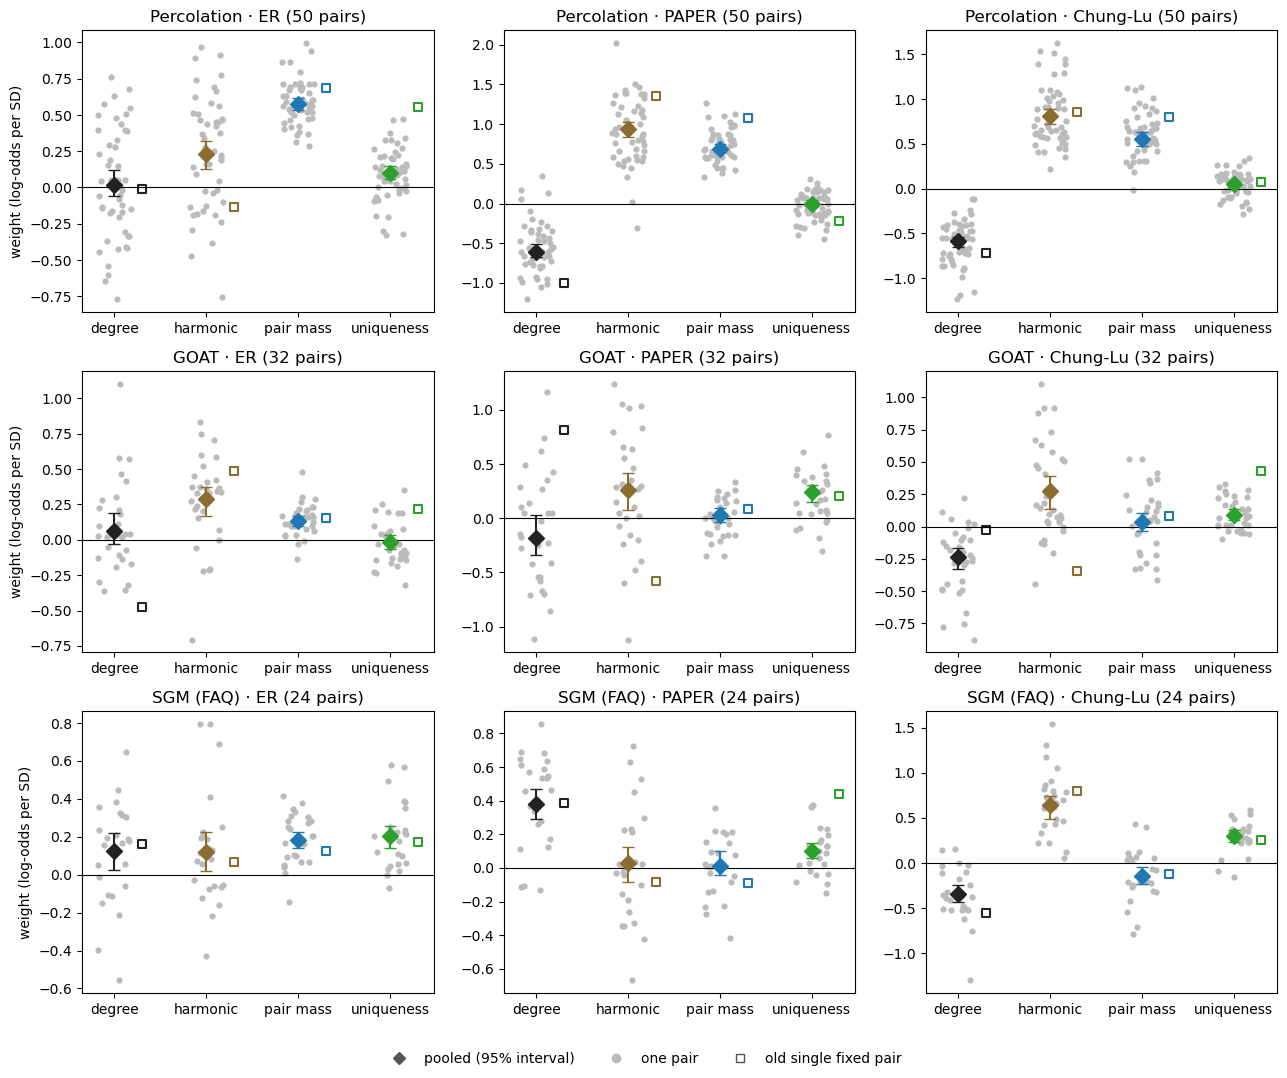

pooled weight  \
algorithm   model    feature                            
Percolation ER       degree      +0.02 [-0.06, +0.12]   
                     harmonic    +0.23 [+0.13, +0.32]   
                     pair mass   +0.57 [+0.53, +0.62]   
                     uniqueness  +0.10 [+0.06, +0.15]   
            PAPER    degree      -0.61 [-0.67, -0.51]   
                     harmonic    +0.94 [+0.83, +1.03]   
                     pair mass   +0.69 [+0.64, +0.75]   
                     uniqueness  -0.01 [-0.05, +0.05]   
            Chung-Lu degree      -0.59 [-0.66, -0.54]   
                     harmonic    +0.81 [+0.73, +0.89]   
                     pair mass   +0.55 [+0.47, +0.63]   
                     uniqueness  +0.06 [+0.02, +0.09]   
GOAT        ER       degree      +0.06 [-0.03, +0.19]   
                     harmonic    +0.29 [+0.17, +0.37]   
                     pair mass   +0.14 [+0.10, +0.17]   
                     uniqueness  -0.01 [-0.07, +0.04]   
            PAPER    degree      -0.18 [-0.34, +0.03]   
                     harmonic    +0.26 [+0.07, +0.42]   
                     pair mass   +0.03 [-0.03, +0.10]   
                     uniqueness  +0.24 [+0.15, +0.31]   
            Chung-Lu degree      -0.24 [-0.33, -0.16]   
                     harmonic    +0.27 [+0.14, +0.39]   
                     pair mass   +0.03 [-0.04, +0.11]   
                     uniqueness  +0.09 [+0.05, +0.13]   
SGM (FAQ)   ER       degree      +0.13 [+0.03, +0.22]   
                     harmonic    +0.12 [+0.02, +0.23]   
                     pair mass   +0.18 [+0.14, +0.22]   
                     uniqueness  +0.20 [+0.14, +0.26]   
            PAPER    degree      +0.38 [+0.29, +0.47]   
                     harmonic    +0.03 [-0.08, +0.12]   
                     pair mass   +0.01 [-0.04, +0.10]   
                     uniqueness  +0.10 [+0.06, +0.15]   
            Chung-Lu degree      -0.34 [-0.44, -0.24]   
                     harmonic    +0.64 [+0.49, +0.74]   
                     pair mass   -0.14 [-0.23, -0.04]   
                     uniqueness  +0.30 [+0.23, +0.37]   

                                pairs with the same sign old single pair  
algorithm   model    feature                                              
Percolation ER       degree                     26 of 50           -0.01  
                     harmonic                   35 of 50           -0.13  
                     pair mass                  50 of 50           +0.68  
                     uniqueness                 37 of 50           +0.55  
            PAPER    degree                     46 of 50           -1.00  
                     harmonic                   49 of 50           +1.36  
                     pair mass                  50 of 50           +1.08  
                     uniqueness                 27 of 50           -0.22  
            Chung-Lu degree                     50 of 50           -0.72  
                     harmonic                   50 of 50           +0.86  
                     pair mass                  49 of 50           +0.80  
                     uniqueness                 31 of 50           +0.08  
GOAT        ER       degree                     20 of 31           -0.48  
                     harmonic                   25 of 31           +0.49  
                     pair mass                  28 of 31           +0.15  
                     uniqueness                 19 of 31           +0.22  
            PAPER    degree                     16 of 29           +0.81  
                     harmonic                   21 of 29           -0.58  
                     pair mass                  15 of 29           +0.09  
                     uniqueness                 23 of 29           +0.20  
            Chung-Lu degree                     27 of 32           -0.03  
                     harmonic                   25 of 32           -0.35  
                     pair mass                  21 of 32           +0.08 

In [4]:
pooled, per_pair, single = {}, {}, {}
for algorithm, model in analysed:
    pooled[(algorithm, model)] = MP.pooled_weights(data, algorithm, model)
    per_pair[(algorithm, model)] = MP.per_pair_weights(data, algorithm, model)
    single[(algorithm, model)] = MP.single_pair_weights(algorithm, model)

algorithms = [a for a in MP.ALGORITHMS if any(s[0] == a for s in analysed)]
if algorithms:
    fig, axes = plt.subplots(len(algorithms), 3, figsize=(13, 3.6 * len(algorithms)), squeeze=False)
    for row, algorithm in enumerate(algorithms):
        for column, model in enumerate(MP.MODELS):
            ax = axes[row, column]
            if (algorithm, model) not in pooled:
                ax.set_visible(False)
                continue
            table, pairs, old = pooled[(algorithm, model)], per_pair[(algorithm, model)], single[(algorithm, model)]
            jitter = np.random.default_rng(0)
            for x, feature in enumerate(FEATURES):
                if not pairs.empty:
                    ax.scatter(x + jitter.uniform(-0.18, 0.18, len(pairs)), pairs[feature], s=12, color='#BBBBBB',
                               zorder=1)
                ax.errorbar(x, table.loc[feature, 'weight'],
                            yerr=[[table.loc[feature, 'weight'] - table.loc[feature, 'low']],
                                  [table.loc[feature, 'high'] - table.loc[feature, 'weight']]],
                            marker='D', markersize=8, color=FEATURE_COLORS[feature], capsize=4, zorder=3)
                if old is not None:
                    ax.scatter(x + 0.3, old[feature], marker='s', s=40, facecolors='white',
                               edgecolors=FEATURE_COLORS[feature], linewidths=1.5, zorder=2)
            ax.axhline(0, color='black', linewidth=0.8)
            ax.set_xticks(range(len(FEATURES)))
            ax.set_xticklabels([MP.FEATURE_LABELS[f] for f in FEATURES])
            n = int(table['pairs'].iloc[0])
            ax.set_title(f"{MP.ALGORITHM_LABELS[algorithm]} · {MP.MODEL_LABELS[model]} ({n} pairs)")
        axes[row, 0].set_ylabel('weight (log-odds per SD)')
    handles = [Line2D([0], [0], marker='D', color='#555555', linestyle='', label='pooled (95% interval)'),
               Line2D([0], [0], marker='o', color='#BBBBBB', linestyle='', label='one pair'),
               Line2D([0], [0], marker='s', color='#555555', markerfacecolor='white', linestyle='',
                      label='old single fixed pair')]
    fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False)
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

    rows = []
    for (algorithm, model), table in pooled.items():
        for feature in FEATURES:
            pairs = per_pair[(algorithm, model)]
            rows.append({'algorithm': MP.ALGORITHM_LABELS[algorithm], 'model': MP.MODEL_LABELS[model],
                         'feature': MP.FEATURE_LABELS[feature],
                         'pooled weight': f"{table.loc[feature, 'weight']:+.2f} "
                                          f"[{table.loc[feature, 'low']:+.2f}, {table.loc[feature, 'high']:+.2f}]",
                         'pairs with the same sign': (f"{int((np.sign(pairs[feature]) == np.sign(table.loc[feature, 'weight'])).sum())}"
                                                      f" of {len(pairs)}") if not pairs.empty else '',
                         'old single pair': (f"{single[(algorithm, model)][feature]:+.2f}"
                                             if single[(algorithm, model)] is not None else '')})
    display(pd.DataFrame(rows).set_index(['algorithm', 'model', 'feature']))
else:
    print(f'No setting has {MIN_PAIRS} complete pairs yet.')

## 3. New pairs: does the score rank seed sets it hasn't seen?

Each pair is scored by a model fitted without it, using 5-fold cross-validation over pairs. This is the honest test of "fit on some graphs, use on another".
- **Table:** AUC within each held-out pair, using its random sets only, averaged over pairs. 0.5 is a coin flip. Degree alone is the comparison.
- **Plot:** success rate against the score's percentile among the pair's 20,000 random pool sets. The right end (top 1% and top 0.1%) is where best of N picks, and it is covered by the tail sets. A curve that keeps rising to the right means screening more random sets keeps paying off.

held-out pairs  AUC, weighted score  AUC, degree only
algorithm   model                                                          
Percolation ER                    50                0.707             0.651
            PAPER                 50                0.737             0.634
            Chung-Lu              50                0.743             0.656
GOAT        ER                    32                0.619             0.614
            PAPER                 32                0.578             0.576
            Chung-Lu              32                0.559             0.526
SGM (FAQ)   ER                    24                0.655             0.641
            PAPER                 24                0.636             0.636
            Chung-Lu              24                0.633             0.609

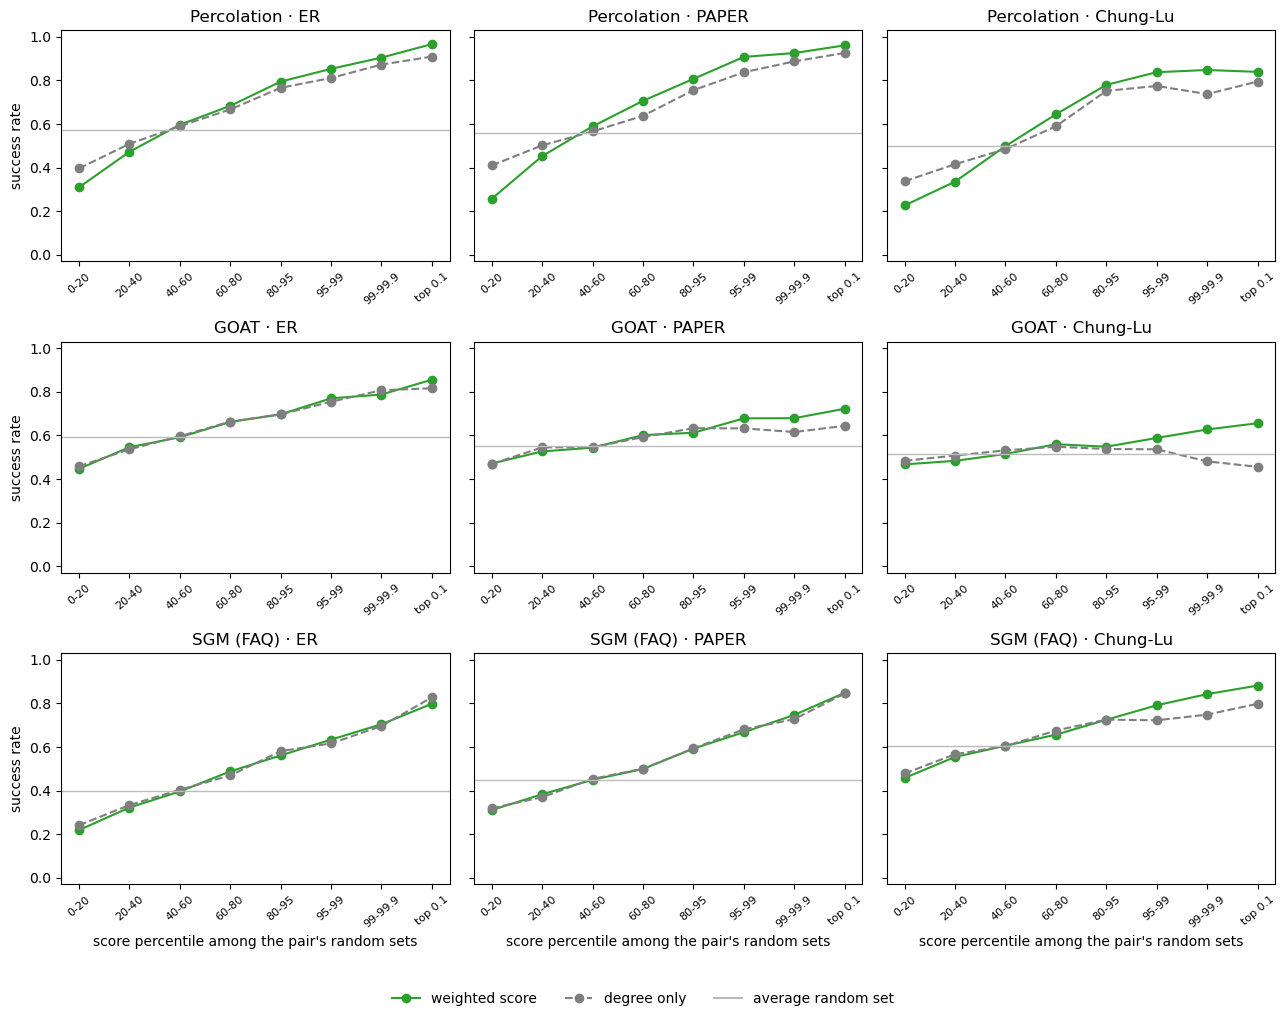

Sets per percentile bin (weighted score), by setting:


percentile,0-20,20-40,40-60,60-80,80-95,95-99,99-99.9,top 0.1
Percolation ER,3013,3022,3102,3428,3938,2511,807,179
Percolation PAPER,3068,3097,3227,3594,3956,2194,711,153
Percolation Chung-Lu,3038,3119,3134,3667,3864,2230,749,199
GOAT ER,1925,1937,2009,2178,2423,1682,528,118
GOAT PAPER,2030,2029,2100,2280,2351,1410,499,101
GOAT Chung-Lu,2428,2297,2255,2350,2197,868,341,64
SGM (FAQ) ER,1440,1459,1417,1492,1748,1477,453,114
SGM (FAQ) PAPER,1435,1456,1415,1481,1782,1505,427,99
SGM (FAQ) Chung-Lu,1472,1491,1537,1743,1918,1001,362,76


In [5]:
held, held_degree, auc_rows = {}, {}, []
for algorithm, model in analysed:
    held[(algorithm, model)] = MP.held_out(data, algorithm, model)
    held_degree[(algorithm, model)] = MP.held_out(data, algorithm, model, features=('degree',))
    auc, n_pairs = MP.within_pair_auc(held[(algorithm, model)])
    auc_degree, _ = MP.within_pair_auc(held_degree[(algorithm, model)])
    auc_rows.append({'algorithm': MP.ALGORITHM_LABELS[algorithm], 'model': MP.MODEL_LABELS[model],
                     'held-out pairs': n_pairs, 'AUC, weighted score': auc, 'AUC, degree only': auc_degree})
if auc_rows:
    display(pd.DataFrame(auc_rows).set_index(['algorithm', 'model']).round(3))

    fig, axes = plt.subplots(len(algorithms), 3, figsize=(13, 3.4 * len(algorithms)), sharey=True, squeeze=False)
    for row, algorithm in enumerate(algorithms):
        for column, model in enumerate(MP.MODELS):
            ax = axes[row, column]
            if (algorithm, model) not in held:
                ax.set_visible(False)
                continue
            for scored, color, style, label in [(held[(algorithm, model)], '#2CA02C', '-', 'weighted score'),
                                                (held_degree[(algorithm, model)], '#7F7F7F', '--', 'degree only')]:
                table = MP.success_by_percentile(scored)
                ax.plot(range(len(table)), table['success'], marker='o', color=color, linestyle=style, label=label)
            random_rate = held[(algorithm, model)].query("group == 'random'")['success'].mean()
            ax.axhline(random_rate, color='#BBBBBB', linewidth=1)
            ax.set_xticks(range(len(MP.PERCENTILE_LABELS)))
            ax.set_xticklabels(MP.PERCENTILE_LABELS, rotation=40, fontsize=8)
            ax.set_ylim(-0.03, 1.03)
            ax.set_title(f"{MP.ALGORITHM_LABELS[algorithm]} · {MP.MODEL_LABELS[model]}")
        axes[row, 0].set_ylabel('success rate')
    for ax in axes[-1]:
        ax.set_xlabel("score percentile among the pair's random sets")
    handles = [Line2D([0], [0], color='#2CA02C', marker='o', label='weighted score'),
               Line2D([0], [0], color='#7F7F7F', marker='o', linestyle='--', label='degree only'),
               Line2D([0], [0], color='#BBBBBB', label='average random set')]
    fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()
    print('Sets per percentile bin (weighted score), by setting:')
    display(pd.DataFrame({f"{MP.ALGORITHM_LABELS[a]} {MP.MODEL_LABELS[m]}": MP.success_by_percentile(held[(a, m)])['sets']
                          for a, m in held}).T)
else:
    print(f'No setting has {MIN_PAIRS} complete pairs yet.')

## 4. Degree-matched contrasts

Each contrast is two random sets with exactly the same number of seed-to-nonseed edges. One is low and one is high in pair mass or uniqueness. Only contrasts where exactly one of the two succeeded count.
- **high wins / low wins:** how often the high or the low set was the one that succeeded.
- **p:** a sign test of high wins against low wins.

Many wins for the high side mean the feature helps beyond degree.

In [6]:
display(MP.contrast_table(data).round(4))

contrasts  high wins  low wins       p
algorithm   model    feature                                           
Percolation ER       pair mass        1250        967         7  0.0000
                     uniqueness       1250        457       176  0.0000
            PAPER    pair mass        1250       1043         3  0.0000
                     uniqueness       1250        479       156  0.0000
            Chung-Lu pair mass        1250        951        12  0.0000
                     uniqueness       1250        534       118  0.0000
GOAT        ER       pair mass         800        248        98  0.0000
                     uniqueness        800        171       170  1.0000
            PAPER    pair mass         800        149       160  0.5695
                     uniqueness        800        179       123  0.0015
            Chung-Lu pair mass         800        226       143  0.0000
                     uniqueness        800        250       126  0.0000
SGM (FAQ)   ER       pair mass         600        207        81  0.0000
                     uniqueness        600        180        93  0.0000
            PAPER    pair mass         600        148       113  0.0351
                     uniqueness        600        179        91  0.0000
            Chung-Lu pair mass         600        182        91  0.0000
                     uniqueness        600        219        85  0.0000

## 5. Save the pooled weights for best of N

This writes `pooled_weights.json` next to the data, with one entry per analysed setting. Best of N z-scores each candidate set against the pair's random sets of the same size, then multiplies by these weights.

In [7]:
if pooled:
    print('Saved', MP.save_weights(pooled))

Saved /Users/langsong/Desktop/Seeded-Graph-Matching/fixed_pair_seed_set_classification/data/multi_pair_2026-10-30/pooled_weights.json
